# Exploratory data analysis: Backblaze Drive Stats (Q1–Q2 2026)

Report Section IV-D. Everything below uses the **training split of seed 0 only** (no validation/test data informs a design choice). All numbers are computed from the real feature store built by `scripts/run_pipeline.py --stage features`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
from IPython.display import Image, display
from tcse.utils import load_config
from tcse.eda import EDA
pd.set_option('display.width', 200)
cfg = load_config('../configs/default.yaml')
eda = EDA(cfg, 'backblaze')
fig = lambda n: display(Image(filename=f'../results/figures/eda_backblaze_{n}.png'))
print('attributes present in training data:', eda.attrs)

attributes present in training data: [5, 9, 193, 194, 197, 198, 199]


## 1. Summary statistics and class ratio per horizon

In [2]:
display(eda.summary_stats())
display(eda.class_ratio())

,attribute,name,missing_pct,mean,std,median,p99,max,nonzero_pct
0,5,Reallocated sectors,0.0,1.999000,75.706001,0.0,5.0,11371.0,3.519
1,9,Power-on hours,0.0,18083.996094,8245.051758,17952.0,36847.0,56187.0,99.998
2,193,Load/unload cycles,0.0,415.197998,416.419006,362.0,1416.0,100917.0,100.000
3,194,Temperature,0.0,33.949001,4.958000,34.0,45.0,54.0,100.000
4,197,Pending sectors,0.0,0.756000,43.265999,0.0,1.0,26752.0,1.106
5,198,Offline uncorrectable,0.0,0.397000,18.138000,0.0,0.0,5755.0,0.367
6,199,UDMA CRC errors,0.0,3.617000,113.885002,0.0,0.0,10204.0,0.476


,H,train_rows,positives,positive_pct,healthy_per_failure,failed_drives_with_positives
0,1,10651263,204,0.0019,52211.1,204
1,7,10294030,1358,0.0132,7579.3,209
2,14,9876930,2632,0.0266,3751.6,212
3,30,8921771,5251,0.0589,1698.1,216


## 2. Missing-data patterns (raw values, before forward fill)

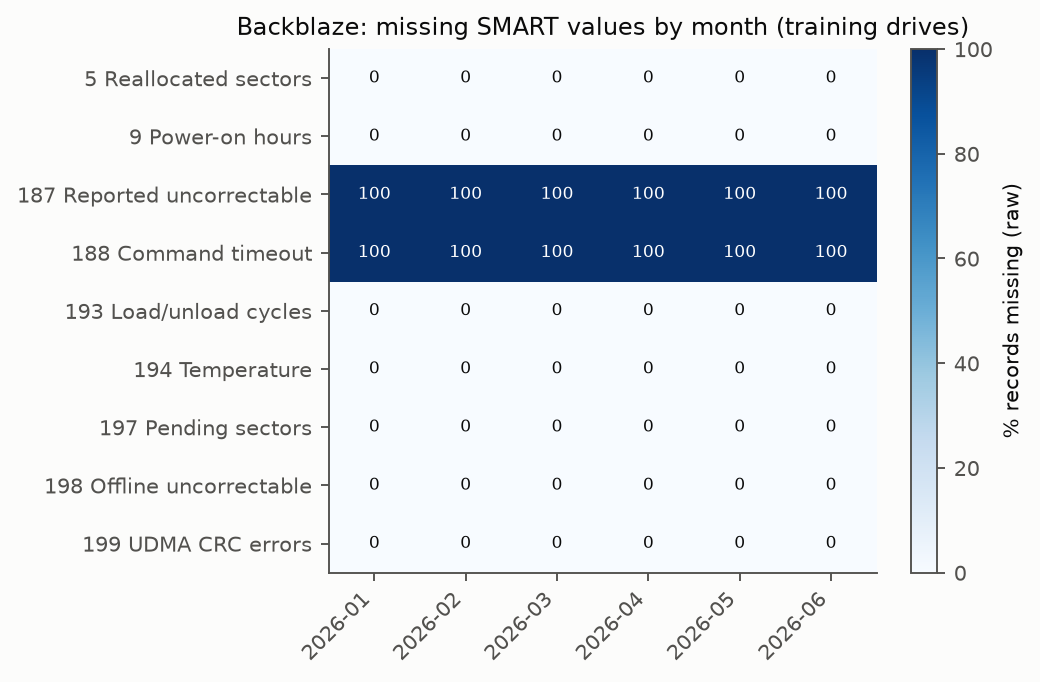

In [3]:
miss = eda.missingness(); fig('missingness')

## 3. Failed vs. healthy drives: box plots and Kolmogorov–Smirnov tests

,attribute,name,n_failed,n_healthy,median_failed,median_healthy,mean_failed,mean_healthy,KS_D,KS_p
4,197,Pending sectors,216,59803,8.0,0.0,737.976868,0.418925,0.577261,1.884735e-68
0,5,Reallocated sectors,216,59803,0.0,0.0,310.412048,1.658228,0.395791,7.012635e-31
1,9,Power-on hours,216,59803,22765.5,17888.0,21837.708984,17977.593750,0.246904,4.972307e-12
2,193,Load/unload cycles,216,59803,243.0,353.0,1403.305542,412.291565,0.108445,1.174424e-02
5,198,Offline uncorrectable,216,59803,0.0,0.0,83.365738,0.326806,0.098273,2.930587e-02
3,194,Temperature,216,59803,34.0,34.0,33.787037,33.941475,0.042032,8.263156e-01
6,199,UDMA CRC errors,216,59803,0.0,0.0,11.875000,3.361086,0.012551,1.000000e+00


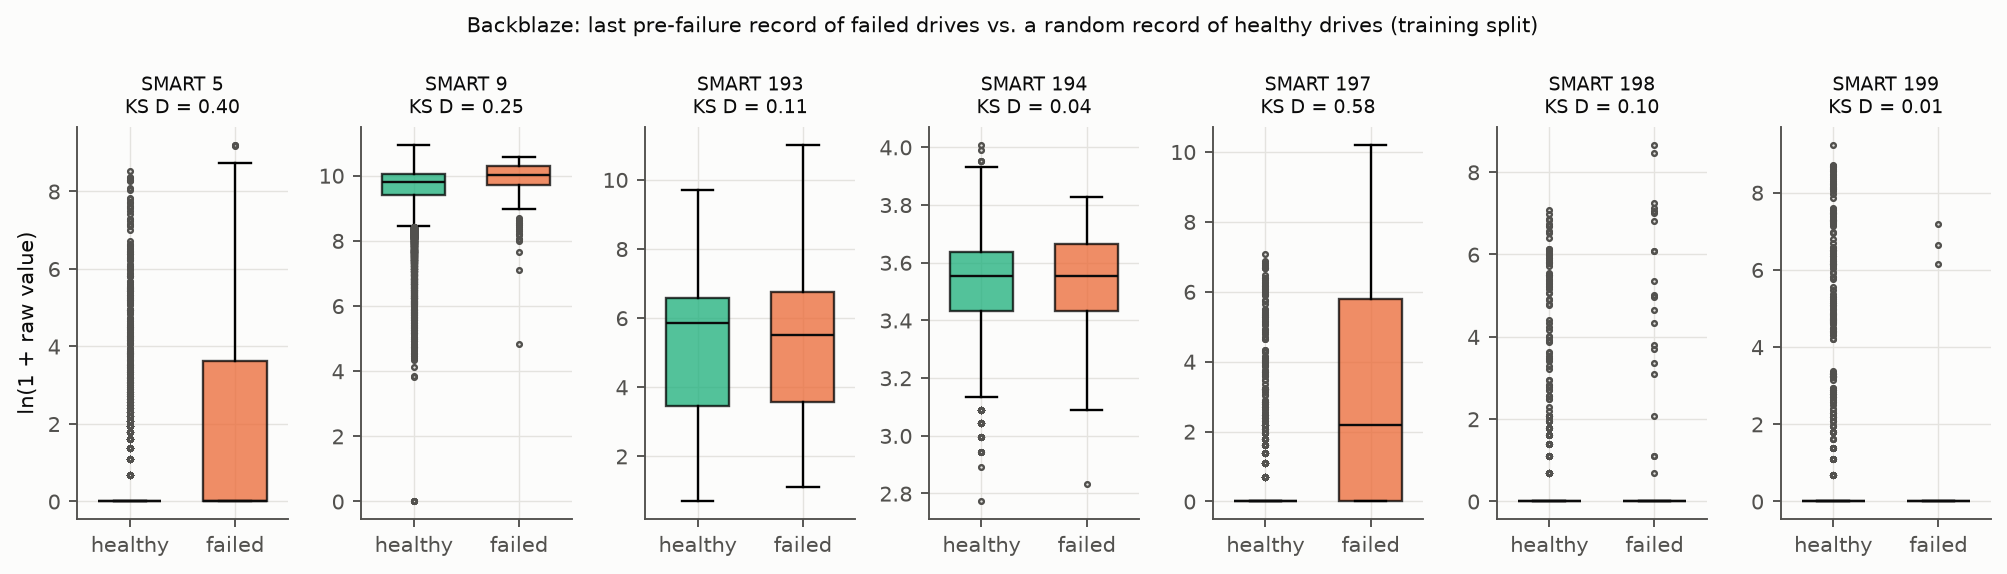

In [4]:
ks = eda.failed_vs_healthy(); display(ks); fig('boxplots_ks')

## 4. Attribute correlations

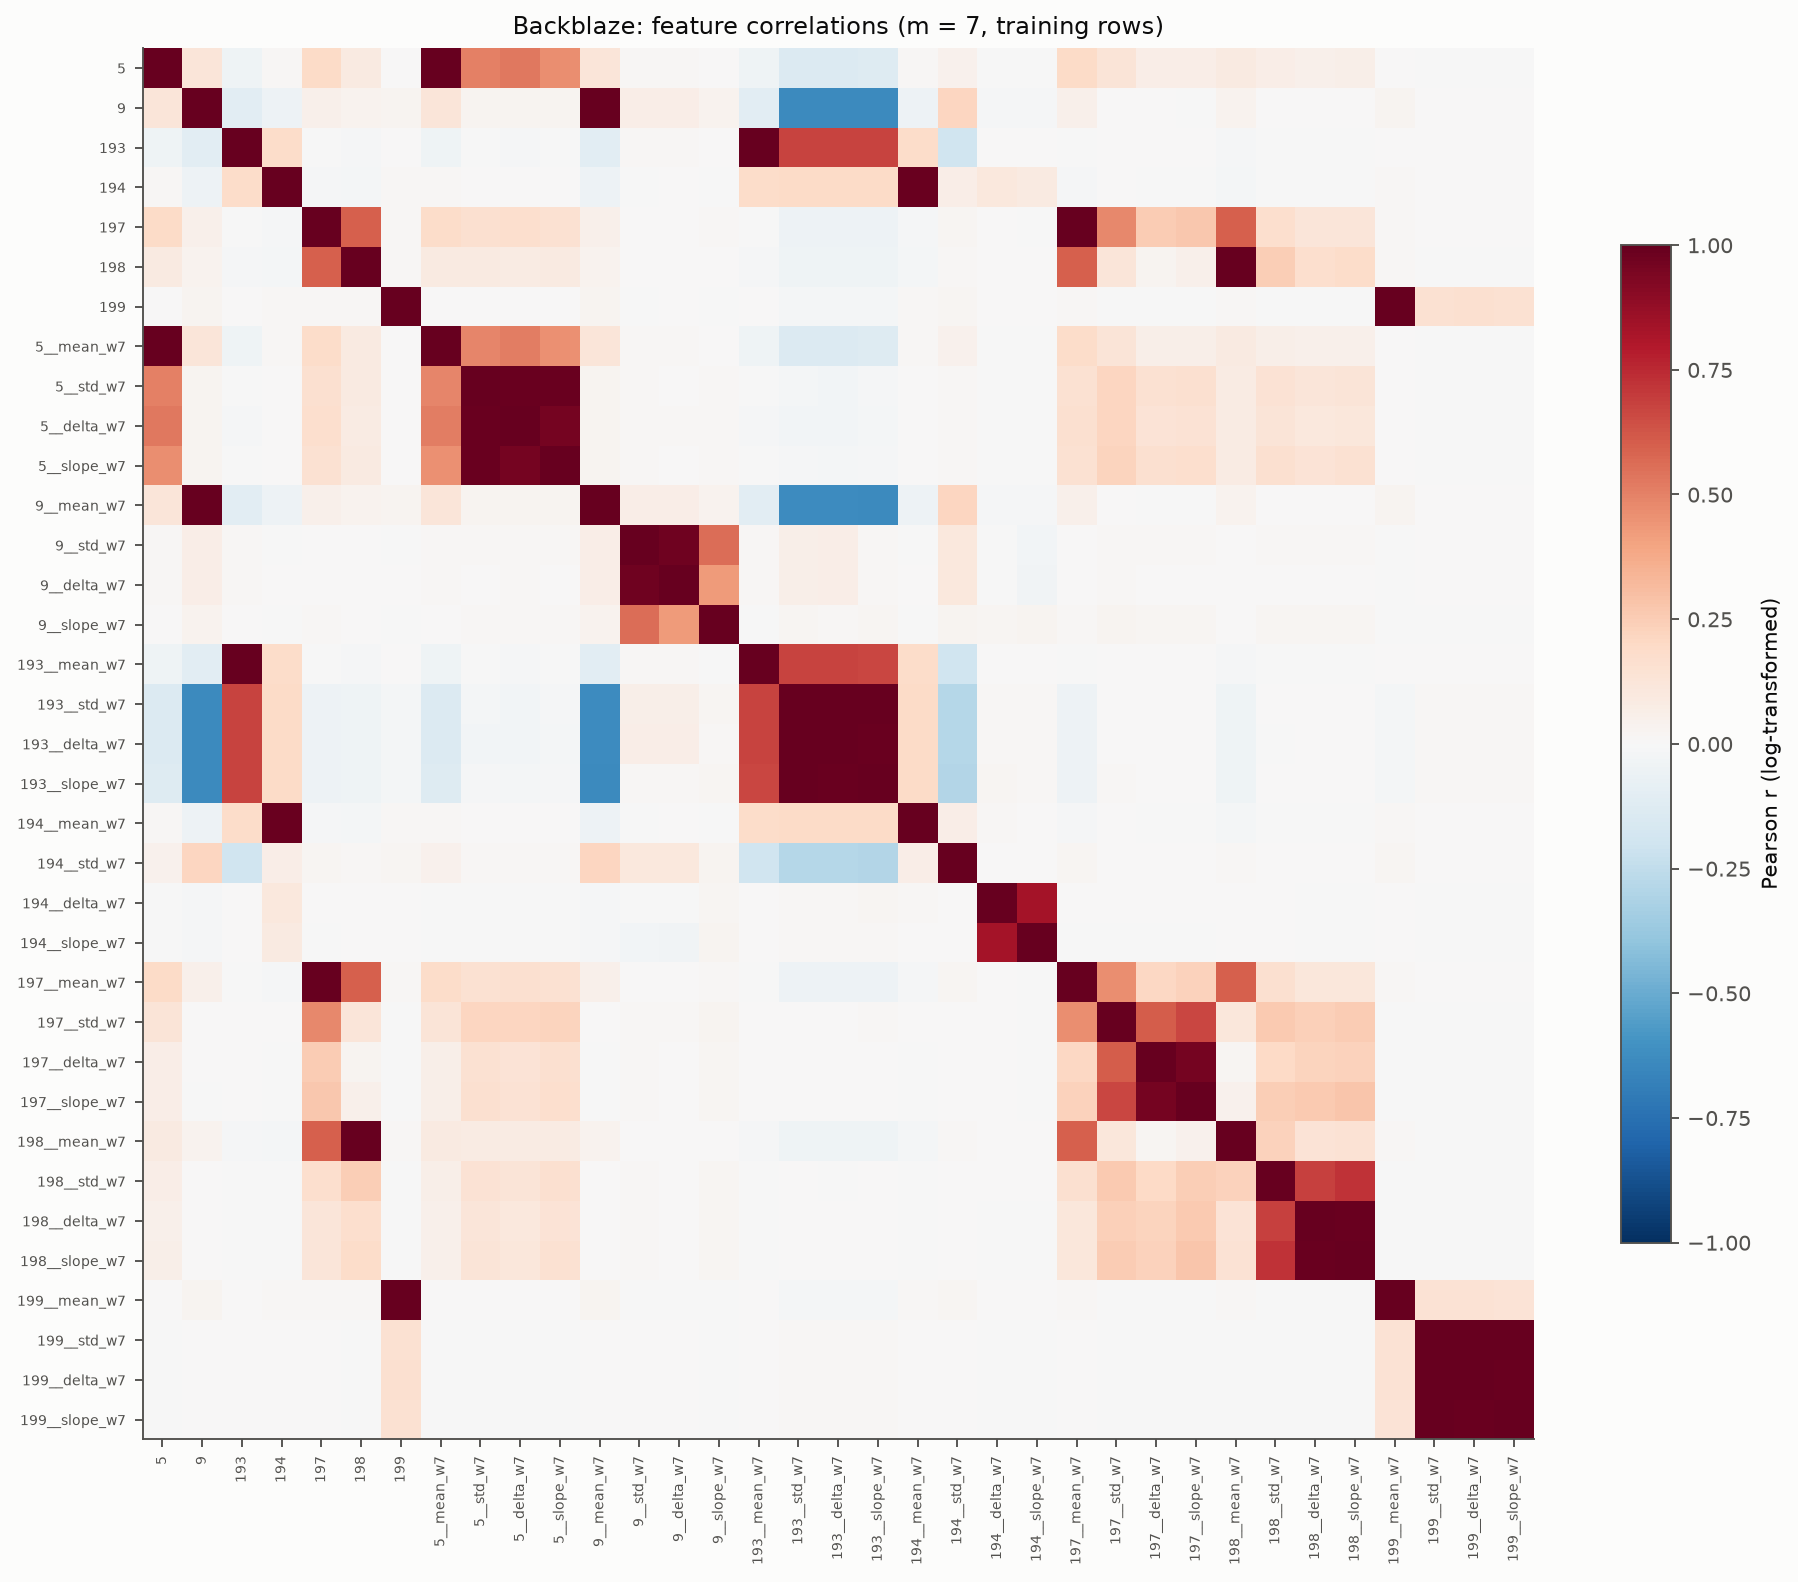

pairs with |r| > 0.95 (one of each is dropped by feature selection):
('smart_5_raw', 'smart_5_raw__mean_w7', np.float64(0.999))
('smart_9_raw', 'smart_9_raw__mean_w7', np.float64(1.0))
('smart_193_raw', 'smart_193_raw__mean_w7', np.float64(1.0))
('smart_194_raw', 'smart_194_raw__mean_w7', np.float64(0.992))
('smart_197_raw', 'smart_197_raw__mean_w7', np.float64(0.997))
('smart_198_raw', 'smart_198_raw__mean_w7', np.float64(0.999))
('smart_199_raw', 'smart_199_raw__mean_w7', np.float64(1.0))
('smart_5_raw__std_w7', 'smart_5_raw__delta_w7', np.float64(0.991))
('smart_5_raw__std_w7', 'smart_5_raw__slope_w7', np.float64(0.985))
('smart_5_raw__delta_w7', 'smart_5_raw__slope_w7', np.float64(0.956))
('smart_9_raw__std_w7', 'smart_9_raw__delta_w7', np.float64(0.974))
('smart_193_raw__std_w7', 'smart_193_raw__delta_w7', np.float64(0.999))
('smart_193_raw__std_w7', 'smart_193_raw__slope_w7', np.float64(0.996))
('smart_193_raw__delta_w7', 'smart_193_raw__slope_w7', np.float64(0.992))
('smart_197_

In [5]:
R, high = eda.correlation(); fig('correlation')
print('pairs with |r| > 0.95 (one of each is dropped by feature selection):')
for h in high: print(h)

## 5. Average 30-day pre-failure trajectories

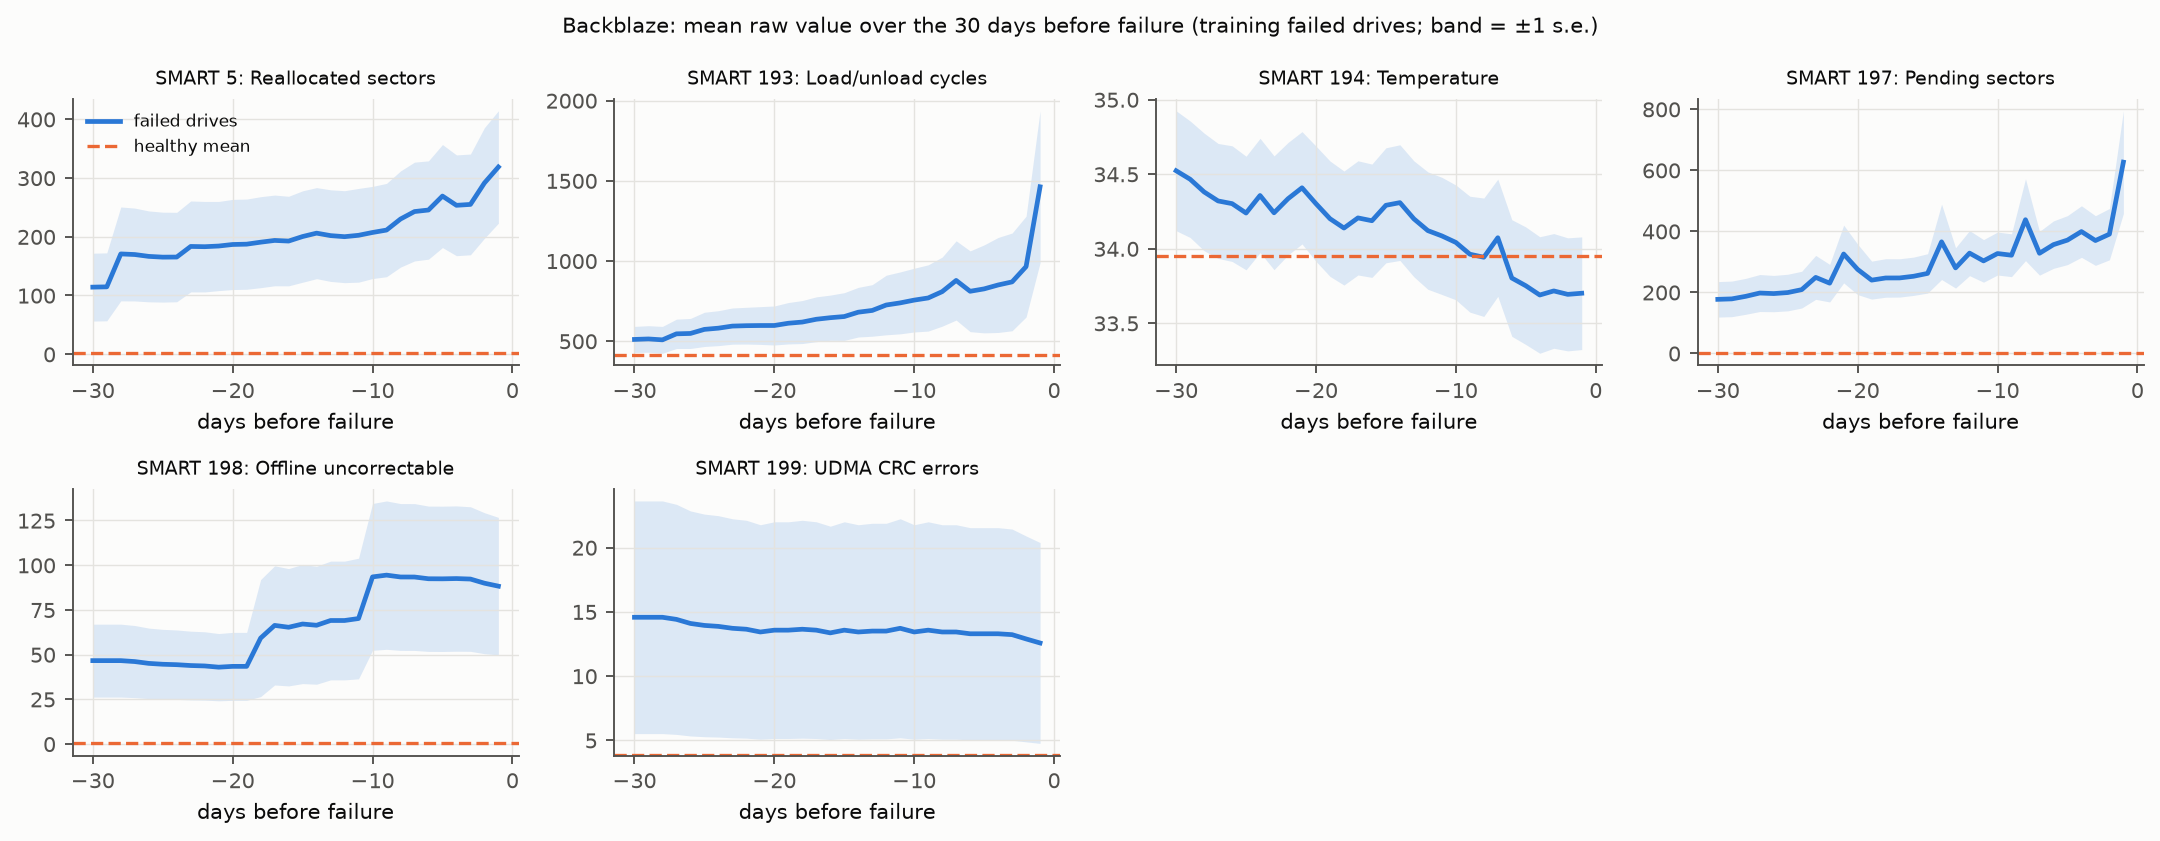

In [6]:
traj = eda.prefailure_trajectories(); fig('prefailure_trajectories')

## 6. Two-dimensional PCA projection

explained variance ratio: [0.178  0.1433]


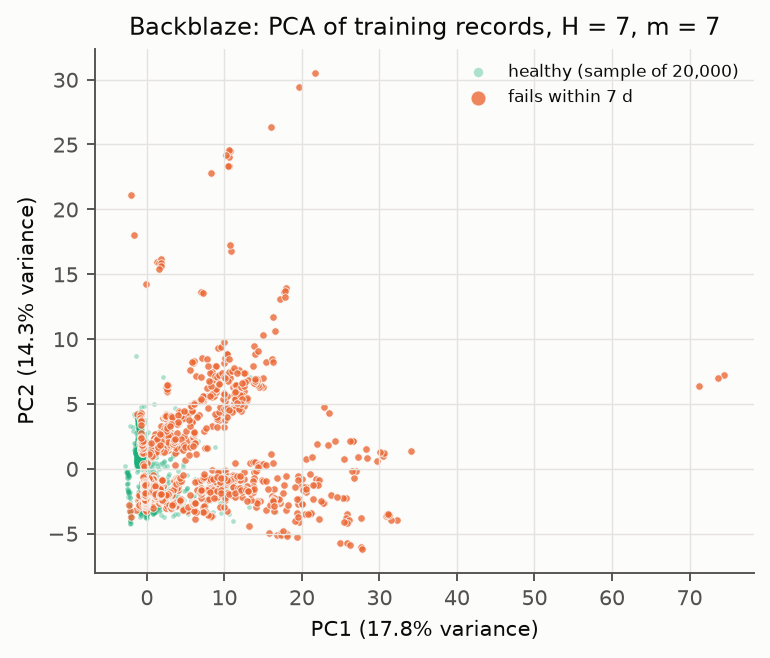

In [7]:
ev = eda.pca(); print('explained variance ratio:', ev.round(4)); fig('pca')

## 7. Choice of the trend window m

KS separation (healthy vs. fails-within-7-days rows) of the delta / slope / std trend features for each candidate window, plus the window chosen on the validation set by `tcse.experiments.select_window` (TCSE validation cost).

In [8]:
piv, summ = eda.window_separation(); display(summ); display(piv)
import json, pathlib
for f in pathlib.Path('../results/metrics/window_selection').glob('backblaze*/chosen.json'): print(f.parent.name, json.loads(f.read_text()))

,mean,median,max
m,,,
3,0.1076,0.0983,0.3098
7,0.1382,0.0793,0.4018
14,0.1530,0.0974,0.4629


m                   3      7      14
attribute stat                      
5         delta  0.161  0.239  0.270
          slope  0.161  0.239  0.270
          std    0.161  0.239  0.270
9         delta  0.098  0.103  0.097
          slope  0.098  0.071  0.062
          std    0.098  0.073  0.066
193       delta  0.218  0.239  0.224
          slope  0.218  0.251  0.252
          std    0.218  0.241  0.224
194       delta  0.013  0.032  0.031
          slope  0.013  0.048  0.046
          std    0.025  0.079  0.115
197       delta  0.229  0.299  0.375
          slope  0.229  0.315  0.384
          std    0.310  0.402  0.463
198       delta  0.003  0.008  0.018
          slope  0.003  0.008  0.018
          std    0.005  0.016  0.029
199       delta  0.000  0.000  0.000
          slope  0.000  0.000  0.000
          std    0.000  0.000  0.000

backblaze {'window': 14, 'val_average_precision': {'3': 0.02072071428077649, '7': 0.03919452248540717, '14': 0.053112302527886526}, 'val_cost': {'3': 3010.0, '7': 2919.0, '14': 2844.0}, 'criterion': 'max TCSE validation average precision (ties: validation cost at r=10), H=7, seed=0'}
